[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/notebooks/lecture4_notebook.ipynb)

# Blockchain Applications — Lecture 4: Stablecoins I: Depeg Risk and On-Chain Early Warning

*Lecture notebook. Daniel Traian Pele, Bucharest University of Economic Studies.*

Can we see a stablecoin depeg coming? This notebook reproduces the estimates, tables and charts of Lecture 4:

1. what a stablecoin promises: supply of US dollar (USD) stablecoins by mechanism and by issuer;
2. measuring the peg: daily deviations of USDT, USDC and DAI, their tails, and the Silicon Valley Bank (SVB) weekend hour by hour;
3. where the price is formed: automated market makers (AMMs), constant product against StableSwap;
4. early warning: episodes, an event-level utility, and a price-only baseline alarm;
5. the last twelve weeks of the USDC/USDT cross rate;
6. further material: a threshold autoregression for the arbitrage band, the Curve 3pool entropy, Gegenbauer scores of a liquidity curve, Pareto tails for a quantile forecast, and the CRPS and twCRPS scores.

Main paper: [Chaffard, Găman, Staures, Ginavar, Jheng, Härdle & Pele (2026), *Onchain Monitoring of Stablecoin Depeg Risk*](https://doi.org/10.5281/zenodo.18339067).
Results marked "paper" are typed in from its tables; every other number is estimated here.

Data: daily and hourly prices from EOD Historical Data (EODHD) and a snapshot of the DefiLlama stablecoin supply data (21 October 2026).
One basis point (bp) is 0.01%, so a price of 0.9990 USD is a deviation of $-10$ bp.

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your Google Drive) and work in that copy.
> Files you create while the notebook runs (CSV files, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/Blockchain_Applications/Lecture_4'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))

## Setup: packages, chart style and data

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

### Data used in this notebook

The deviation analysis uses the same sample end as the lecture, 23 October 2026.
The helper `ohlc()` reads the full daily file (open, high, low, close), because the intraday low is needed below; `daily()` and `hourly()` come from the setup cell.

In [4]:
import gzip
import json
import urllib.request
import matplotlib.dates as mdates
from scipy import stats

END = '2026-10-23'                       # last day of the lecture sample
END_HOUR = '2026-10-23 23:00'            # last hour of the hourly sample
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def ohlc(sym, start=None, end=END):
    """Daily open, high, low and close from data/market/<sym>.csv."""
    x = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')
    return x.loc[start:end]


def finish_fig(fig, name, ncol=3, bottom=0.12):
    """Legend below the plot, room for it, then save and show."""
    legend_below(fig, ncol=ncol)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## 1. What a stablecoin promises

A stablecoin is a token that targets a fixed price $P^\ast$ in a reference asset, here $P^\ast = 1$ USD. Three mechanisms hold the peg:

- **fiat-backed** (USDT, USDC): reserves in cash and Treasury bills; the issuer mints and redeems at par for eligible clients;
- **crypto-backed** (DAI/USDS): over-collateralised loans in a smart contract; liquidations protect the peg;
- **algorithmic** (TerraUSD until May 2022): a mint/burn swap against a volatile token, without external collateral.

Arbitrage keeps the market price near 1: if $P_t < 1$, buy on the market and redeem at 1; if $P_t > 1$, mint at 1 and sell.
Arbitrage needs access (know-your-customer (KYC) rules, minimum sizes), time (bank hours) and trust in the reserves; when one of the three fails, the price can leave the peg.

### Who issues the dollars on chain

The DefiLlama snapshot holds the total circulating supply of USD stablecoins and the supply of each large token, with its peg mechanism.
We add up the supply by mechanism; the part of the total that is not covered by the tokens in the snapshot is shown separately.
The right panel gives the share of each of the eight largest issuers in the total on the last day of the snapshot.

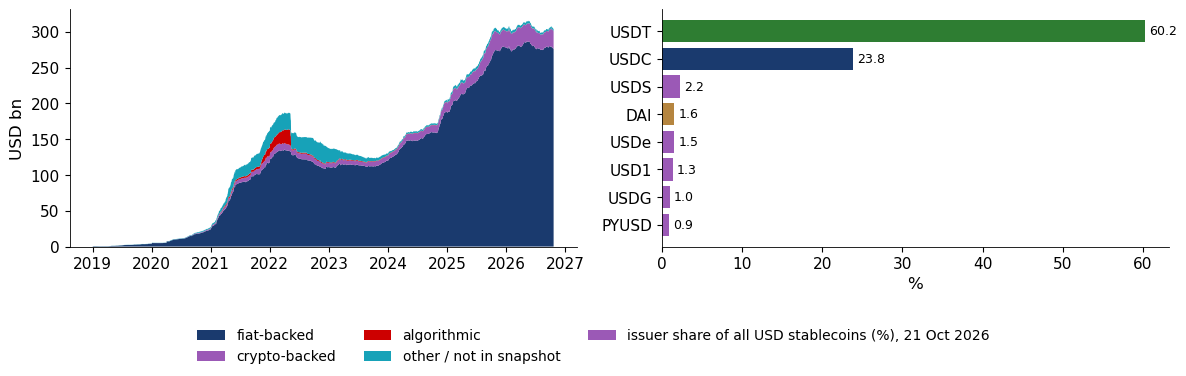

last day of the snapshot: 2026-10-21, total supply of USD stablecoins = 303.4 bn USD
total supply on 2020-01-01: 4.2 bn USD
total supply on 2022-05-01: 187.1 bn USD
total supply on 2023-03-01: 134.5 bn USD
total supply on 2024-01-01: 129.8 bn USD
total supply on 2025-01-01: 203.2 bn USD
share of the total by mechanism (%): {'algorithmic': 0.0, 'crypto-backed': 8.1, 'fiat-backed': 90.9, 'other / not in snapshot': 0.9}
share of the total by issuer (%): {'USDT': 60.2, 'USDC': 23.8, 'USDS': 2.2, 'DAI': 1.6, 'USDe': 1.5, 'USD1': 1.3, 'USDG': 1.0, 'PYUSD': 0.9}
USDT + USDC together: 84.0% of all USD stablecoins


In [5]:
SNAP = 'stablecoin16-20261021-979c073f25783889.json.gz'
src = data_file('snapshots', SNAP)
raw = open(src, 'rb').read() if os.path.exists(src) else urllib.request.urlopen(src).read()
P_ = json.loads(gzip.decompress(raw))['payloads']
assets = {a['id']: a for a in P_['list']['peggedAssets']}


def supply(key):
    """Circulating supply in USD of one entry of the snapshot, daily."""
    s = pd.Series({pd.to_datetime(int(x['date']), unit='s'): (x.get('totalCirculatingUSD') or {}).get('peggedUSD', np.nan)
                   for x in P_[key]})
    return s.sort_index()


tot = supply('all').loc['2019-01-01':]
ids = [k for k in P_ if k.startswith('id_')]
panel = pd.DataFrame({k: supply(k) for k in ids}).reindex(tot.index)
mech = {k: assets[k[3:]]['pegMechanism'].replace('crytpo', 'crypto') for k in ids}
by = panel.T.groupby(pd.Series(mech)).sum(min_count=1).T
by['other / not in snapshot'] = (tot - by.sum(axis=1)).clip(lower=0)
order = ['fiat-backed', 'crypto-backed', 'algorithmic', 'other / not in snapshot']
cur = pd.Series({assets[k[3:]]['symbol']: panel[k].dropna().iloc[-1] for k in ids if panel[k].notna().any()}).sort_values(ascending=False)
sh = 100 * cur.head(8) / tot.iloc[-1]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].stackplot(by.index, [by[c].fillna(0) / 1e9 for c in order], colors=[BLUE, ETH, RED, TEAL], labels=order)
ax[0].set_ylabel('USD bn')
ax[1].barh(sh.index[::-1], sh.values[::-1], color=[COL.get(s, ETH) for s in sh.index[::-1]],
           label=f'issuer share of all USD stablecoins (%), {tot.index[-1]:%d %b %Y}')
for i, v in enumerate(sh.values[::-1]):
    ax[1].text(v + 0.5, i, f'{v:.1f}', va='center', fontsize=9)
ax[1].set_xlabel('%')
finish_fig(fig, 'ba_l4_supply', ncol=3, bottom=0.17)

print(f'last day of the snapshot: {tot.index[-1].date()}, total supply of USD stablecoins = {tot.iloc[-1] / 1e9:.1f} bn USD')
for y in ['2020-01-01', '2022-05-01', '2023-03-01', '2024-01-01', '2025-01-01']:
    i = tot.index.get_indexer([pd.Timestamp(y)], method='nearest')[0]
    print(f'total supply on {tot.index[i].date()}: {tot.iloc[i] / 1e9:.1f} bn USD')
print('share of the total by mechanism (%):', (100 * by.iloc[-1] / tot.iloc[-1]).round(1).to_dict())
print('share of the total by issuer (%):', sh.round(1).to_dict())
print(f'USDT + USDC together: {sh["USDT"] + sh["USDC"]:.1f}% of all USD stablecoins')

Fiat-backed tokens make up about 91% of the supply and crypto-backed tokens about 8%; algorithmic designs almost vanished after TerraUSD.
Two issuers, Tether (USDT) and Circle (USDC), hold about 84% of all USD stablecoins, so a dislocation of USDC against USDT is a system-level event.

## 2. Measuring the peg

### Definitions

The deviation from the peg in basis points, for a token against the dollar and for USDC priced in USDT, is

$$ d_t = 10^4\,(P_t - 1), \qquad d_t^{\,\mathrm{USDC/USDT}} = 10^4\left(\frac{P_t^{\mathrm{USDC}}}{P_t^{\mathrm{USDT}}} - 1\right). $$

The closing price shows what remained at the end of the day; the intraday low shows the worst price at which someone traded.
For a threshold $\delta$ (here 15 bp), the empirical exceedance probability and the breach indicator are

$$ \hat P(|d| \geq x) = \frac1T \sum_{t=1}^T \mathbb 1\{|d_t| \geq x\}, \qquad b_t = \mathbb 1\{|d_t| \geq \delta\}. $$

An **episode** starts at the first breach hour after at least 24 hours without a breach. Hours inside one episode are not independent observations, so we count episodes, not hours.

### Peg deviations, daily, 2021–2026

The table reports, for each coin, the mean, median and standard deviation (sd) of the daily deviation of the close, its 1% and 99% quantiles, the minimum and its date, the share of days with $|d_t| \geq 15$ bp and $\geq 50$ bp, the deepest intraday low, the share of days whose low was at least 50 bp below the peg, the excess kurtosis and the first-order autocorrelation $\hat\rho_1$.
Earlier years are left out because the EODHD aggregate price then includes illiquid venues.

In [6]:
dv, lo = {}, {}
for s in ['USDT', 'USDC', 'DAI']:
    x = ohlc(f'{s}-USD.CC', '2021-01-01', END)
    dv[s], lo[s] = 1e4 * (x['close'] - 1), 1e4 * (x['low'] - 1)
dv, lo = pd.DataFrame(dv), pd.DataFrame(lo)
rows = {}
for s in dv:
    x, l = dv[s], lo[s]
    rows[s] = {'days': len(x), 'mean (bp)': x.mean(), 'median (bp)': x.median(), 'sd (bp)': x.std(),
               'q 1% (bp)': x.quantile(0.01), 'q 99% (bp)': x.quantile(0.99), 'min close (bp)': x.min(),
               'date of min': x.idxmin().date(), 'max close (bp)': x.max(),
               '% days |d| >= 15': 100 * (x.abs() >= 15).mean(), '% days |d| >= 50': 100 * (x.abs() >= 50).mean(),
               'min intraday low (bp)': l.min(), '% days low <= -50': 100 * (l <= -50).mean(),
               'excess kurtosis': stats.kurtosis(x), 'autocorrelation lag 1': x.autocorr(1)}
D_tab = pd.DataFrame(rows).T
print(f'Daily deviation d = 10^4 (P - 1), closes from {dv.index[0].date()} to {dv.index[-1].date()}')
D_tab.round(2)

Daily deviation d = 10^4 (P - 1), closes from 2021-01-01 to 2026-10-23


,days,mean (bp),median (bp),sd (bp),q 1% (bp),q 99% (bp),min close (bp),date of min,max close (bp),% days |d| >= 15,% days |d| >= 50,min intraday low (bp),% days low <= -50,excess kurtosis,autocorrelation lag 1
USDT,2122,0.464204,0.920361,7.306748,-15.507229,21.29979,-41.278609,2022-05-11,115.2966,3.628652,0.141376,-515.138921,0.282752,40.022889,0.731548
USDC,2122,-0.225821,-0.207179,7.422151,-7.569719,9.690392,-285.0,2023-03-11,104.9621,0.659755,0.141376,-1226.0,0.188501,1045.009359,0.290329
DAI,2122,0.358954,-0.774002,10.768329,-17.179494,36.582972,-261.31348,2023-03-11,103.104,5.230914,0.565504,-1029.967719,1.696513,184.804422,0.336002


How to read the table:

- the mean is zero to the first decimal: the peg holds *on average*; the risk is in the tails;
- USDC has a kurtosis above 1,000: one weekend (SVB, March 2023) dominates its distribution, while its 1% quantile is only about $-7.6$ bp;
- USDT has the smallest extreme but the most persistent deviations ($\hat\rho_1 \approx 0.73$) and is the coin most often beyond 15 bp after 2022;
- the worst intraday lows are 4 to 12 times deeper than the worst closes. A liquidation engine sees the low, not the close.

### The three dollars, day by day

Closes in colour, intraday lows in red (clipped at $-150$ bp so that the scale stays readable), and the $\pm 15$ bp band.

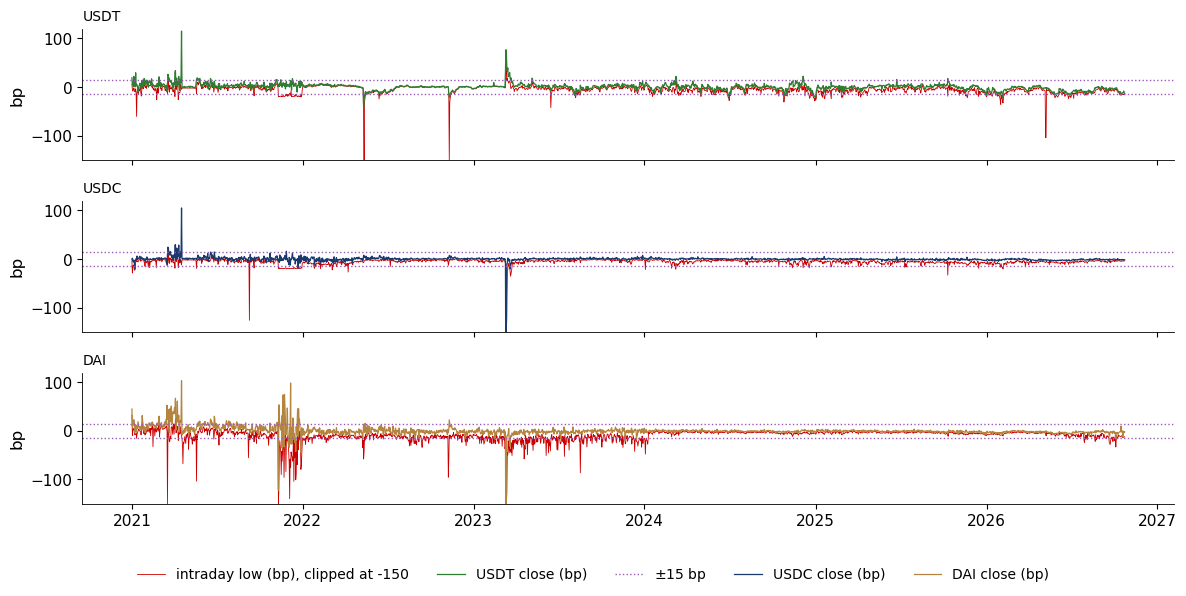

In [7]:
fig, axs = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
for ax, s in zip(axs, dv):
    ax.plot(lo.index, lo[s].clip(lower=-150), color=RED, lw=0.6, label=('intraday low (bp), clipped at -150' if s == 'USDT' else None))
    ax.plot(dv.index, dv[s], color=COL[s], lw=0.9, label=f'{s} close (bp)')
    for h in (15, -15):
        ax.axhline(h, color=ETH, ls=':', lw=1, label=('$\\pm$15 bp' if (s == 'USDT' and h == 15) else None))
    ax.set_ylim(-150, 120); ax.set_ylabel('bp'); ax.set_title(s, fontsize=10, loc='left')
finish_fig(fig, 'ba_l4_dev_daily', ncol=5, bottom=0.08)

Closes stay inside $\pm 15$ bp most of the time; the lows reveal the stress days: May 2022 (Terra) and March 2023 (SVB).

### Tails and their frequency

Left: the exceedance curve $\hat P(|d_t| \geq x)$ on log-log axes, for closes (solid) and intraday lows (dashed).
Right: the share of days in each year with $|d_t| \geq 15$ bp.

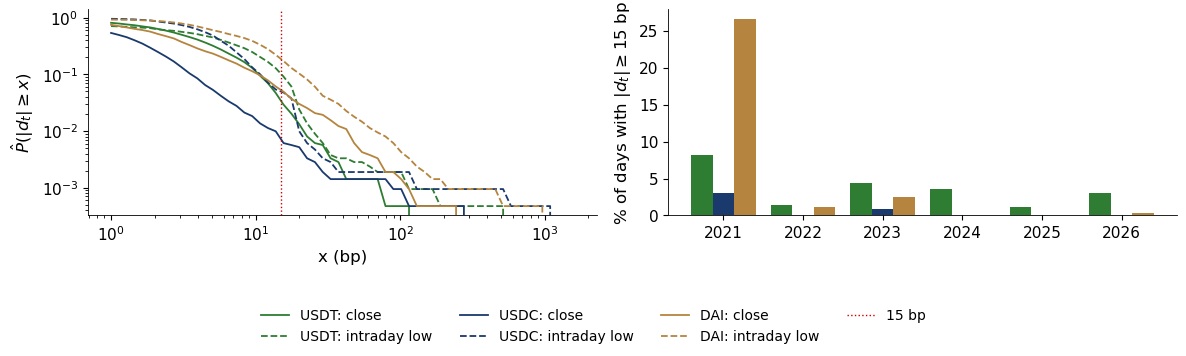

share of days with |d| >= 15 bp, by year (%):


,USDT,USDC,DAI
date,,,
2021,8.2,3.0,26.6
2022,1.4,0.0,1.1
2023,4.4,0.8,2.5
2024,3.6,0.0,0.0
2025,1.1,0.0,0.0
2026,3.0,0.0,0.3


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
xs = np.logspace(0, 3.2, 60)
for s in dv:
    ax[0].loglog(xs, [(dv[s].abs() >= x).mean() for x in xs], color=COL[s], label=f'{s}: close')
    ax[0].loglog(xs, [(lo[s] <= -x).mean() for x in xs], color=COL[s], ls='--', label=f'{s}: intraday low')
ax[0].axvline(15, color=RED, ls=':', lw=1, label='15 bp')
ax[0].set_xlabel('x (bp)'); ax[0].set_ylabel(r'$\hat P(|d_t| \geq x)$')
yrs = dv.abs().ge(15).groupby(dv.index.year).mean() * 100
w = 0.27
for i, s in enumerate(dv):
    ax[1].bar(yrs.index + (i - 1) * w, yrs[s], width=w, color=COL[s])
ax[1].set_ylabel(r'% of days with $|d_t| \geq 15$ bp'); ax[1].set_xticks(yrs.index)
finish_fig(fig, 'ba_l4_exceed', ncol=4, bottom=0.2)
print('share of days with |d| >= 15 bp, by year (%):')
yrs.round(1)

On log-log axes the exceedance curves decay roughly linearly beyond 15 bp: a power-law tail, as in Lecture 2.
DAI was beyond 15 bp on about a quarter of the days in 2021 and almost never in 2026; USDT is the only coin that still breaches regularly.

### The SVB weekend, hour by hour

From here on we use hourly closes from January 2022 to 23 October 2026. The cross rate USDC priced in USDT, $d_t^{\mathrm{USDC/USDT}}$, is the price on which the paper's alarm is built.
On Friday 10 March 2023 Silicon Valley Bank (SVB) failed; on the evening of 10 March Circle disclosed that 3.3 bn USD of its reserves were at SVB; on Sunday 12 March the Federal Reserve (Fed), the Federal Deposit Insurance Corporation (FDIC) and the Treasury announced a backstop for all SVB deposits.
All times are Coordinated Universal Time (UTC).

hourly grid: 2022-01-01 00:00:00 to 2026-10-23 23:00:00, 42168 hours; hours with USDC or USDT missing: 2.80%


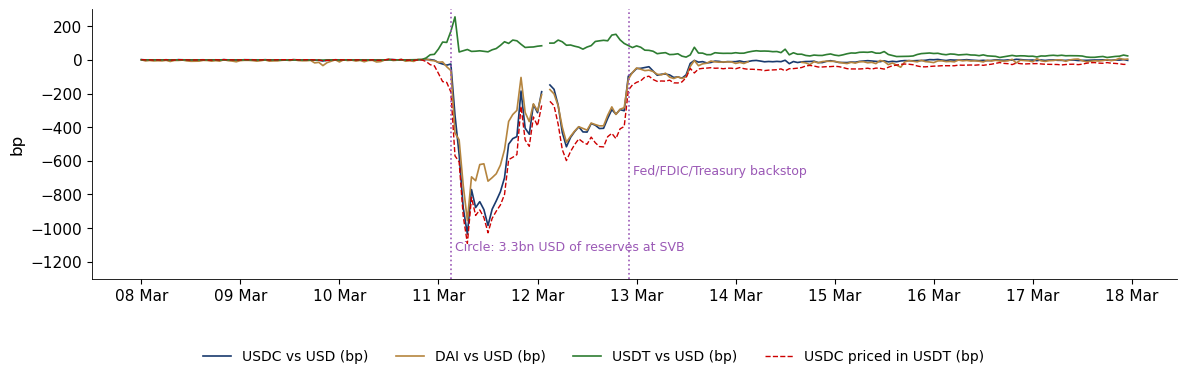

USDC: lowest hourly deviation -1036 bp at 2023-03-11 07:00:00 UTC; highest 3.6 bp
DAI: lowest hourly deviation -955 bp at 2023-03-11 07:00:00 UTC; highest 9.4 bp
USDT: lowest hourly deviation -2 bp at 2023-03-09 19:00:00 UTC; highest 255.9 bp
USDC first hour back above -100 bp: 2023-03-12 22:00:00 UTC
USDC first hour back above -15 bp:  2023-03-13 14:00:00 UTC


In [9]:
H = pd.concat({'USDC': hourly('USDC-USD.CC'), 'USDT': hourly('USDT-USD.CC'), 'DAI': hourly('DAI-USD.CC'),
               'BTC': hourly('BTC-USD.CC')}, axis=1)
H = H.loc['2022-01-01':]                                           # hourly sample of the lecture: January 2022 onwards
H = H.reindex(pd.date_range(H.index[0], END_HOUR, freq='h'))       # regular hourly grid, cut at the lecture's sample end
dh = 1e4 * (H['USDC'] / H['USDT'] - 1)                              # USDC priced in USDT, bp
print(f'hourly grid: {H.index[0]} to {H.index[-1]}, {len(H)} hours; '
      f'hours with USDC or USDT missing: {100 * H[["USDC", "USDT"]].isna().any(axis=1).mean():.2f}%')

z = H.loc['2023-03-08':'2023-03-17']
fig, ax = plt.subplots(figsize=(12, 3.8))
for s in ['USDC', 'DAI', 'USDT']:
    ax.plot(z.index, 1e4 * (z[s] - 1), color=COL[s], lw=1.2, label=f'{s} vs USD (bp)')
ax.plot(z.index, 1e4 * (z['USDC'] / z['USDT'] - 1), color=RED, ls='--', lw=1, label='USDC priced in USDT (bp)')
for t_, lab, yy in [('2023-03-11 03:00', 'Circle: 3.3bn USD of reserves at SVB', -1150), ('2023-03-12 22:15', 'Fed/FDIC/Treasury backstop', -700)]:
    ax.axvline(pd.Timestamp(t_), color=ETH, ls=':', lw=1.2)
    ax.text(pd.Timestamp(t_), yy, ' ' + lab, fontsize=9, color=ETH, va='bottom')
ax.set_ylabel('bp'); ax.set_ylim(-1300, 300)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
finish_fig(fig, 'ba_l4_svb', ncol=4, bottom=0.14)

zz = 1e4 * (z[['USDC', 'DAI', 'USDT']] - 1)
for s in zz:
    print(f'{s}: lowest hourly deviation {zz[s].min():.0f} bp at {zz[s].idxmin()} UTC; highest {zz[s].max():.1f} bp')
back = zz['USDC'].loc[zz['USDC'].idxmin():]
print('USDC first hour back above -100 bp:', back[back > -100].index[0], 'UTC')
print('USDC first hour back above -15 bp: ', back[back > -15].index[0], 'UTC')

USDC and DAI reached their lowest hourly close at the same hour on Saturday 11 March, while USDT rose slightly above 1: a flight to the other dollar.
USDC was back above $-100$ bp just before the backstop was announced and above $-15$ bp only on Monday 13 March.
DAI followed USDC because a large part of its collateral was USDC: contagion through the balance sheet.

### Worked example: was the SVB discount fair?

Circle disclosed 3.3 bn USD of about 40 bn USD of reserves at SVB, a share $s = 3.3/40$. With a recovery rate $R$ on the SVB deposit, the redemption value per token is

$$ V(R) = 1 - s\,(1 - R). $$

In [10]:
s_svb = 3.3 / 40
for R_ in [0, 0.5, 0.9]:
    V = 1 - s_svb * (1 - R_)
    print(f'recovery rate R = {R_:.1f}: redemption value V = {V:.4f} USD, implied deviation {1e4 * (V - 1):.0f} bp')
low = zz['USDC'].min()
print(f'lowest hourly USDC deviation: {low:.0f} bp; distance below the zero-recovery value: {-(low - 1e4 * (-s_svb)):.0f} bp')

recovery rate R = 0.0: redemption value V = 0.9175 USD, implied deviation -825 bp
recovery rate R = 0.5: redemption value V = 0.9587 USD, implied deviation -413 bp
recovery rate R = 0.9: redemption value V = 0.9918 USD, implied deviation -82 bp
lowest hourly USDC deviation: -1036 bp; distance below the zero-recovery value: 211 bp


The market went below the value under *zero* recovery. The extra discount of about 211 bp is a liquidity premium: banks were closed over the weekend, so redemption was impossible and arbitrage could not work.
The discount priced time and uncertainty, not only the expected loss. A peg can fail with reserves that cover 92% or more of the tokens: access matters as much as backing.

## 3. Where the price is formed: automated market makers

On decentralised exchanges the price is set by an **automated market maker** (AMM): a smart contract that holds two (or more) tokens and trades along a fixed curve.

### Constant product

A pool holds $x$ of token X and $y$ of token Y, and every trade keeps $x\,y = k$. The marginal price of X in Y is $p = y/x$. Selling $\Delta x$ returns

$$ \Delta y = y - \frac{k}{x + \Delta x} = \frac{y\,\Delta x}{x + \Delta x}, \qquad \text{slippage} = 1 - \frac{\Delta y}{\Delta x} = \frac{\Delta x}{x + \Delta x} \quad (\text{at } p = 1). $$

### StableSwap (Curve)

For $n$ coins and amplification coefficient $A$, the StableSwap invariant ([Egorov, 2019](https://curve.fi/files/stableswap-paper.pdf)) is

$$ A\,n^n \sum_i x_i + D = A\,D\,n^n + \frac{D^{n+1}}{n^n \prod_i x_i}. $$

As $A \to 0$ it becomes the constant product; as $A \to \infty$ it becomes the constant sum $x + y = D$, with a price of exactly 1.
For two coins we solve the invariant numerically for $y$ given $x$, and get the marginal price from the implicit function theorem, $p = -dy/dx = F_x / F_y$.
The pool below holds 10 million (m) X and 10 m Y.

In [11]:
from scipy.optimize import brentq

D0 = 20.0                                      # pool of 10m + 10m


def ss_y(x, A, D=D0):
    """Balance of Y that keeps the 2-coin StableSwap invariant for a balance x of X."""
    f = lambda y: 4 * A * (x + y) + D - 4 * A * D - D ** 3 / (4 * x * y)
    return brentq(f, 1e-12, 10 * D)


def ss_price(x, A, D=D0):
    """Marginal price of X in units of Y, -dy/dx."""
    y = ss_y(x, A, D)
    Fx = 4 * A + D ** 3 / (4 * x ** 2 * y)
    Fy = 4 * A + D ** 3 / (4 * x * y ** 2)
    return Fx / Fy, y


print(f'constant product, sell 1m X into 10m + 10m: receive {10 * 1 / 11:.3f}m Y, slippage {100 / 11:.1f}%')
tab = {}
for q in [0.1, 1, 5, 8, 9.5]:
    row = {'constant product': 10 - 100 / (10 + q)}
    for A in [10, 100, 2000]:
        row[f'A = {A}'] = 10 - ss_y(10 + q, A)
    tab[f'{q}m'] = {k: 100 * (1 - v / q) for k, v in row.items()}
print('Average slippage (%) for a sale of X into a pool of 10m X + 10m Y:')
pd.DataFrame(tab).T.round(3)

constant product, sell 1m X into 10m + 10m: receive 0.909m Y, slippage 9.1%
Average slippage (%) for a sale of X into a pool of 10m X + 10m Y:


,constant product,A = 10,A = 100,A = 2000
0.1m,0.990,0.048,0.005,0.000
1m,9.091,0.478,0.050,0.003
5m,33.333,2.951,0.329,0.017
8m,44.444,7.221,1.042,0.055
9.5m,48.718,11.592,2.938,0.232


StableSwap is thousands of times cheaper near balance, but slippage rises steeply when the pool empties of one coin.

### Prices are inelastic until they are not

Left: the marginal price of X as a function of its share in the pool. Right: the average slippage as a function of the size of the sale (log scale).

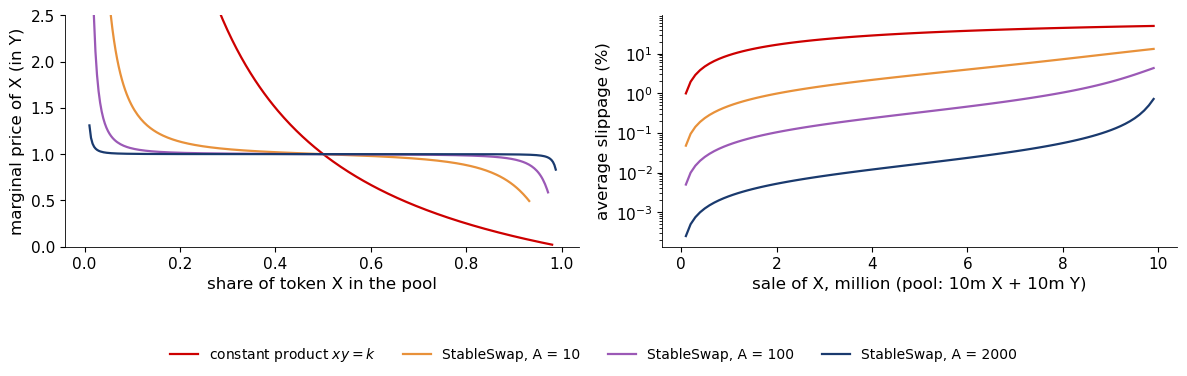

A = 100: price of X when X is 80% of the pool = 0.986
A = 100: price of X when X is 90% of the pool = 0.943
A = 100: price of X when X is 95% of the pool = 0.807
A = 2000: price of X when X is 80% of the pool = 0.999
A = 2000: price of X when X is 90% of the pool = 0.997
A = 2000: price of X when X is 95% of the pool = 0.988


In [12]:
shares = np.linspace(0.02, 0.98, 300)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(shares, (1 - shares) / shares, color=RED, lw=1.6, label='constant product $xy = k$')
for A, col in [(10, BTC), (100, ETH), (2000, BLUE)]:
    pts = []
    for x in np.linspace(0.2, 19.8, 300):
        p, y = ss_price(x, A)
        pts.append((x / (x + y), p))
    pts = np.array(pts)
    ax[0].plot(pts[:, 0], pts[:, 1], lw=1.6, color=col, label=f'StableSwap, A = {A}')
ax[0].set_xlabel('share of token X in the pool'); ax[0].set_ylabel('marginal price of X (in Y)'); ax[0].set_ylim(0, 2.5)
qs = np.linspace(0.1, 9.9, 100)
ax[1].plot(qs, [100 * (1 - (10 - 100 / (10 + q)) / q) for q in qs], color=RED, lw=1.6)
for A, col in [(10, BTC), (100, ETH), (2000, BLUE)]:
    ax[1].plot(qs, [100 * (1 - (10 - ss_y(10 + q, A)) / q) for q in qs], color=col, lw=1.6)
ax[1].set_xlabel('sale of X, million (pool: 10m X + 10m Y)'); ax[1].set_ylabel('average slippage (%)'); ax[1].set_yscale('log')
finish_fig(fig, 'ba_l4_amm', ncol=4, bottom=0.17)

for A in [100, 2000]:
    for s_target in [0.8, 0.9, 0.95]:
        x = brentq(lambda x: x / (x + ss_y(x, A)) - s_target, 10.0, 19.99)
        print(f'A = {A}: price of X when X is {s_target:.0%} of the pool = {ss_price(x, A)[0]:.3f}')

With $A = 100$ the price of X is still 0.986 when X makes up 80% of the pool; with $A = 2000$ it is 0.988 even at 95%.
The pool absorbs one-sided flow with almost no price change, so the *price* hides the stress; the *composition* of the pool shows it.

## 4. Early warning

### Data and target

The paper uses the Uniswap V3 USDC/USDT pool (0.01% fee), hourly, January 2022 – May 2026, with feature blocks from the pool, the Curve 3pool, Aave and the broader market.
The target is a breach of $\delta = 15$ bp within the next 24 hours:

$$ y_t = \mathbb 1\Big\{\max_{1 \leq h \leq 24} |d_{t+h}| \geq \delta\Big\}. $$

We build the same target on the EODHD cross rate USDC/USDT. First, the number of episodes and of breach hours for four thresholds, by year.

In [13]:
def episodes(dd, th):
    """Start times of episodes: first breach hour after at least 24 hours without a breach."""
    b = dd.abs() >= th
    ev, last = [], None
    for t_ in dd.index[b.fillna(False)]:
        if last is None or (t_ - last) > pd.Timedelta(hours=24):
            ev.append(t_)
        last = t_
    return pd.DatetimeIndex(ev)


evtab = {}
for th in [10, 15, 25, 50]:
    e = episodes(dh, th)
    evtab[th] = {'episodes': len(e), 'breach hours': int((dh.abs() >= th).sum()),
                 **{f'episodes in {y}': int((e.year == y).sum()) for y in range(2022, 2027)}}
E = pd.DataFrame(evtab).T
E.index.name = 'threshold delta (bp)'
y24 = (dh.abs() >= 15).astype(float)[::-1].rolling(24, min_periods=1).max()[::-1].shift(-1)
print(f'positive 24-hour labels at 15 bp: {int(y24.sum())} of {int(y24.notna().sum())} hours ({100 * y24.mean():.1f}%)')
E

positive 24-hour labels at 15 bp: 3010 of 42167 hours (7.1%)


,episodes,breach hours,episodes in 2022,episodes in 2023,episodes in 2024,episodes in 2025,episodes in 2026
threshold delta (bp),,,,,,,
10,119,4282,37,10,38,14,20
15,50,1044,21,7,14,3,5
25,8,358,4,2,1,1,0
50,3,105,2,1,0,0,0


Between 10 and 15 bp the number of episodes falls by more than half; beyond 25 bp there are only 8 in five years.
The threshold is a policy choice: a low $\delta$ gives many, mostly harmless events; a high $\delta$ leaves too few events to learn from or to test on.
The paper counts 2,227 positive hours but 107 events in the pool; the aggregated EODHD price shows about half as many events. The venue matters.

### Evaluating an alarm, not a classifier

The area under the receiver operating characteristic curve (AUC) and the area under the precision–recall curve (AUPRC) score each hour separately, so they reward correct labels *during* an episode; an alert after the breach is no warning. The paper uses an event-level protocol instead:

- alerts are the hours with a score above a threshold; a 24-hour refractory period merges them into alert episodes;
- event $e$ at time $\tau_e$ is detected if an alert falls in $[\tau_e - 24\text{h}, \tau_e - 1\text{h}]$; its lead $\ell_e$ is the number of hours before $\tau_e$;
- all other alert episodes are false; $F_m$ is the number of false alerts per month.

The utility is

$$ U = \frac{1}{|E|}\sum_{e \in E} v(\ell_e) - 0.05\,F_m, \qquad v(\ell) = 0.10 + 0.90\,\frac{\ell - 1}{23} \;\text{ for } 1 \leq \ell \leq 24, \text{ else } 0 . $$

The alert threshold is chosen on a validation period, maximising $U$ subject to $F_m \leq 2$ per month, and is never re-tuned on the test period.

### Worked example: computing the utility

Four events; the first valid alerts come 14 h, 2 h, never and 20 h before the breach; there are 2.5 false alerts per month.

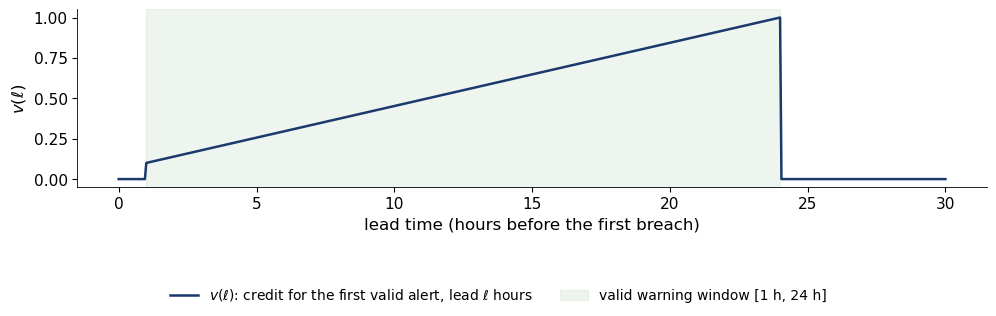

credit per event v(l): [0.609 0.139 0.    0.843]
mean credit = 0.398; utility U = 0.398 - 0.05 x 2.5 = 0.273


In [14]:
def v(l):
    """Credit for the first valid alert with lead l hours."""
    l = np.asarray(l, dtype=float)
    return np.where((l >= 1) & (l <= 24), 0.10 + 0.90 * (l - 1) / 23, 0.0)


fig, ax = plt.subplots(figsize=(10, 3.2))
ll = np.linspace(0, 30, 601)
ax.plot(ll, v(ll), color=BLUE, lw=1.8, label=r'$v(\ell)$: credit for the first valid alert, lead $\ell$ hours')
ax.axvspan(1, 24, color=GREEN, alpha=0.08, label='valid warning window [1 h, 24 h]')
ax.set_xlabel('lead time (hours before the first breach)'); ax.set_ylabel(r'$v(\ell)$')
finish_fig(fig, 'ba_l4_utility', ncol=2, bottom=0.2)

leads = np.array([14, 2, 0, 20])
print('credit per event v(l):', np.round(v(leads), 3))
print(f'mean credit = {v(leads).mean():.3f}; utility U = {v(leads).mean():.3f} - 0.05 x 2.5 = {v(leads).mean() - 0.05 * 2.5:.3f}')

One more false alert per month costs 0.05, about the credit for detecting one extra event (out of four) with a 2-hour lead.

### Results in the paper: four classifier families

The paper trains four tree-based classifiers (CatBoost, random forest, XGBoost, LightGBM) on the on-chain features, with a class-weight parameter $\alpha$.
The chart shows the event utility with its 95% confidence interval (CI) on the test period, from Table 1 of the paper.

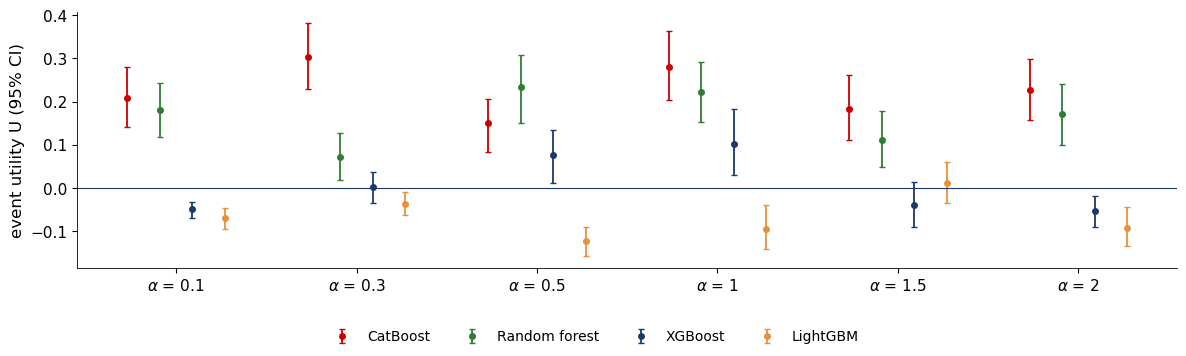

In [15]:
T1 = {  # model: [(alpha, U, lower CI, upper CI, recall, false alerts per month)], Chaffard et al. (2026), Table 1
    'CatBoost': [(0.1, .208, .142, .279, .568, 2.30), (0.3, .303, .229, .381, .723, 2.50), (0.5, .149, .084, .206, .517, 2.33),
                 (1, .281, .204, .363, .746, 3.07), (1.5, .183, .110, .261, .589, 3.10), (2, .226, .157, .298, .685, 2.70)],
    'Random forest': [(0.1, .180, .118, .243, .410, 0.97), (0.3, .071, .018, .127, .160, 0.76), (0.5, .233, .150, .308, .489, 1.45),
                      (1, .222, .152, .291, .515, 1.79), (1.5, .111, .049, .178, .305, 1.49), (2, .170, .100, .241, .437, 1.93)],
    'XGBoost': [(0.1, -.049, -.069, -.033, 0, .99), (0.3, .002, -.035, .037, .186, 1.59), (0.5, .076, .012, .133, .516, 3.46),
                (1, .101, .029, .182, .544, 3.73), (1.5, -.040, -.091, .014, .206, 3.28), (2, -.055, -.090, -.020, .055, 1.75)],
    'LightGBM': [(0.1, -.071, -.096, -.047, .030, 1.60), (0.3, -.037, -.064, -.010, .054, 1.19), (0.5, -.124, -.158, -.090, .032, 2.69),
                 (1, -.096, -.143, -.041, .105, 3.05), (1.5, .010, -.035, .060, .118, 1.34), (2, -.093, -.136, -.045, .095, 2.96)]}
fig, ax = plt.subplots(figsize=(12, 3.6))
off = {'CatBoost': -0.27, 'Random forest': -0.09, 'XGBoost': 0.09, 'LightGBM': 0.27}
cols = {'CatBoost': RED, 'Random forest': GREEN, 'XGBoost': BLUE, 'LightGBM': BTC}
for name, rows_ in T1.items():
    a = np.arange(6) + off[name]
    Uv, lo_, hi_ = (np.array([r_[j] for r_ in rows_]) for j in (1, 2, 3))
    ax.errorbar(a, Uv, yerr=[Uv - lo_, hi_ - Uv], fmt='o', color=cols[name], capsize=2, ms=4, label=name)
ax.axhline(0, color=BLUE, lw=0.8)
ax.set_xticks(range(6)); ax.set_xticklabels([r'$\alpha$ = ' + str(r_[0]) for r_ in T1['CatBoost']])
ax.set_ylabel('event utility U (95% CI)')
finish_fig(fig, 'ba_l4_paper_t1', ncol=4, bottom=0.12)

The best model in the paper, CatBoost with $\alpha = 0.3$, detects 72% of the events with a median lead of 14.4 hours and 2.5 false alerts a month ($U = 0.303$).
The random forest with $\alpha = 0.1$ has the *higher* AUC (0.901 against 0.862) but detects only 41% of the events: AUC is not the right criterion for an alarm.

### A price-only baseline

We apply the same protocol to the EODHD cross rate, using only price information:

- features: $d_t$, $|d_t|$, the 24-hour maximum of $|d|$, the 24-hour volatility of $\Delta d$, the deviation from the 168-hour (weekly) mean, DAI and USDT against USD, the 24-hour BTC return and its annualised 24-hour volatility;
- training 2022–2023, validation 2024 (alert threshold chosen there under $F_m \leq 2$), test 2 January 2025 – 23 October 2026, with 24-hour gaps (embargoes) between the periods;
- models: a logistic regression on standardised features and a gradient-boosting classifier; a simple rule $|d_t| \geq k$ with $k$ chosen on 2024.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score

F = pd.DataFrame(index=H.index)
F['d'] = dh
F['absd'] = dh.abs()
F['max24'] = dh.abs().rolling(24, min_periods=12).max()
F['sd24'] = dh.diff().rolling(24, min_periods=12).std()
F['dev168'] = dh - dh.rolling(168, min_periods=84).mean()
F['dai'] = 1e4 * (H['DAI'] - 1)
F['usdt'] = 1e4 * (H['USDT'] - 1)
rb = np.log(H['BTC']).diff()
F['btcvol24'] = rb.rolling(24, min_periods=12).std() * np.sqrt(24 * 365) * 100
F['btcret24'] = 100 * (np.log(H['BTC']) - np.log(H['BTC']).shift(24))
F['y'] = y24
F = F.dropna()
tr = F.loc[:'2023-12-30 23:00']; va = F.loc['2024-01-02':'2024-12-31 23:00']; te = F.loc['2025-01-02':]
cols = [c for c in F if c != 'y']
ev_all = episodes(dh, 15)
print(f'training hours {len(tr)}, validation hours {len(va)}, test hours {len(te)}; share of positive labels in the test period {100 * te["y"].mean():.2f}%')


def evaluate(score, thr):
    """Event-level evaluation: alert episodes (24 h refractory), credit in [tau - 24h, tau - 1h], false alerts per month, U."""
    a = score.index[score.values >= thr]
    alerts, last = [], None
    for t_ in a:
        if last is None or (t_ - last) >= pd.Timedelta(hours=24):
            alerts.append(t_); last = t_
    alerts = pd.DatetimeIndex(alerts)
    evs = ev_all[(ev_all >= score.index[0] + pd.Timedelta(hours=24)) & (ev_all <= score.index[-1])]
    used, leads = set(), []
    for tau in evs:
        win = alerts[(alerts >= tau - pd.Timedelta(hours=24)) & (alerts <= tau - pd.Timedelta(hours=1))]
        if len(win):
            leads.append((tau - win[0]) / pd.Timedelta(hours=1)); used.update(win)
        else:
            leads.append(0)
    months = (score.index[-1] - score.index[0]) / pd.Timedelta(days=30.44)
    fa = len([a_ for a_ in alerts if a_ not in used]) / months
    leads = np.array(leads)
    det = leads > 0
    return {'events': len(evs), 'detected': int(det.sum()), 'recall': det.mean() if len(evs) else np.nan,
            'median lead (h)': float(np.median(leads[det])) if det.any() else np.nan,
            'false alerts per month': fa, 'utility U': (v(leads).mean() if len(leads) else 0) - 0.05 * fa, 'alerts': len(alerts)}

training hours 16303, validation hours 8580, test hours 14958; share of positive labels in the test period 1.89%


In [17]:
models = {'logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.5)),
          'gradient boosting': HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, random_state=0)}
ew, scores = {}, {}
for name, mdl in models.items():
    mdl.fit(tr[cols], tr['y'])
    sv = pd.Series(mdl.predict_proba(va[cols])[:, 1], index=va.index)
    best = None
    for thr in np.unique(np.quantile(sv, np.linspace(0.80, 0.999, 120))):     # threshold chosen on 2024 only
        res = evaluate(sv, thr)
        if res['false alerts per month'] <= 2 and (best is None or res['utility U'] > best[1]['utility U']):
            best = (thr, res)
    st = pd.Series(mdl.predict_proba(te[cols])[:, 1], index=te.index)
    scores[name] = st
    ew[name] = {'alert threshold': best[0], **evaluate(st, best[0]),
                'AUC': roc_auc_score(te['y'], st), 'AUPRC': average_precision_score(te['y'], st)}

vrule = pd.Series(va['absd'].values, index=va.index)
vk = [(k, evaluate(vrule, k)) for k in range(4, 21)]
print('rule |d_t| >= k on the 2024 validation year (k in bp: recall, false alerts per month):')
print({k: (round(r_['recall'], 2), round(r_['false alerts per month'], 2)) for k, r_ in vk})
kbest = max([x for x in vk if x[1]['false alerts per month'] <= 2], key=lambda x: x[1]['utility U'])[0]
naive = pd.Series(te['absd'].values, index=te.index)
ew[f'rule |d_t| >= {kbest} bp'] = {'alert threshold': kbest, **evaluate(naive, kbest),
                                   'AUC': roc_auc_score(te['y'], naive), 'AUPRC': average_precision_score(te['y'], naive)}
EW = pd.DataFrame(ew).T
print(f'\nTest period {te.index[0].date()} to {te.index[-1].date()}, events: first hour with |d| >= 15 bp after 24 quiet hours')
EW.astype(float).round(3)

rule |d_t| >= k on the 2024 validation year (k in bp: recall, false alerts per month):
{4: (np.float64(0.93), 19.35), 5: (np.float64(0.93), 16.68), 6: (np.float64(0.86), 13.68), 7: (np.float64(0.86), 11.59), 8: (np.float64(0.79), 9.34), 9: (np.float64(0.79), 7.17), 10: (np.float64(0.79), 6.01), 11: (np.float64(0.79), 4.42), 12: (np.float64(0.71), 3.75), 13: (np.float64(0.64), 3.17), 14: (np.float64(0.43), 2.59), 15: (np.float64(0.0), 2.17), 16: (np.float64(0.0), 1.92), 17: (np.float64(0.0), 1.75), 18: (np.float64(0.0), 1.5), 19: (np.float64(0.0), 1.17), 20: (np.float64(0.0), 0.75)}

Test period 2025-01-02 to 2026-10-23, events: first hour with |d| >= 15 bp after 24 quiet hours


,alert threshold,events,detected,recall,median lead (h),false alerts per month,utility U,alerts,AUC,AUPRC
logistic regression,0.718,8.0,1.0,0.125,2.0,0.600,-0.013,14.0,0.928,0.308
gradient boosting,0.999,8.0,0.0,0.000,NaN,0.000,0.000,0.0,0.898,0.325
rule |d_t| >= 20 bp,20.000,8.0,0.0,0.000,NaN,0.185,-0.009,4.0,0.905,0.411


All three alarms have an AUC near or above 0.9, yet they give almost no timely warnings. The high AUC comes from labelling hours *inside* episodes, which is easy once the deviation is already large.
In 2024 every rule that detected events produced at least 2.6 false alerts a month, so the budget of 2 per month forced the threshold above 15 bp, where a rule can no longer warn before a 15 bp breach.
The standardised coefficients of the logistic regression show which features carry the score:

In [18]:
coef = pd.Series(models['logistic regression'][-1].coef_[0], index=cols).sort_values()
print('logistic regression, coefficients on standardised features:')
coef.round(3).to_frame('coefficient')

logistic regression, coefficients on standardised features:


,coefficient
btcret24,-0.324
usdt,0.002
dai,0.189
dev168,0.284
btcvol24,0.317
sd24,1.795
d,1.814
absd,7.366
max24,7.371


### The recall–false-alert trade-off

With hindsight we can trace every threshold on the test period: the share of events detected in time (recall) against the number of false alert episodes per month.
These curves are a diagnostic only, since they use the test data to set the threshold. The star is the paper's best model, estimated on another sample with on-chain features.

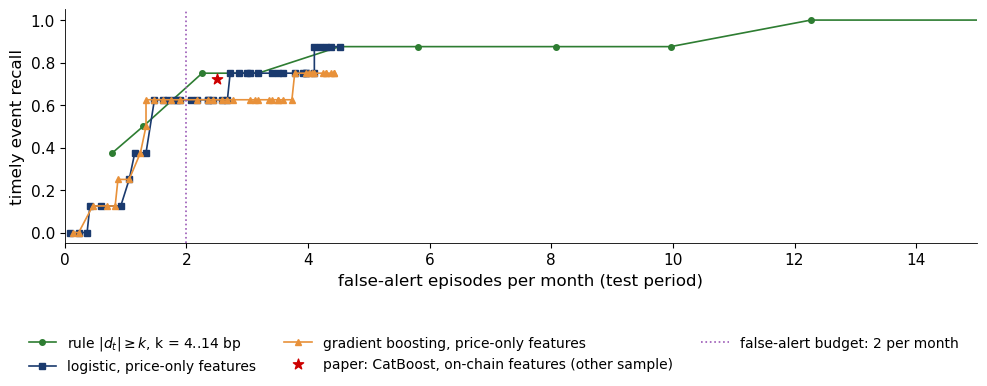

,detected,recall,median lead (h),false alerts per month,utility U
rule threshold k (bp),,,,,
4,8,1.000,11.0,19.512,-0.455
5,8,1.000,5.5,15.729,-0.422
6,8,1.000,8.0,12.270,-0.215
7,7,0.875,6.0,9.963,-0.239
8,7,0.875,12.0,8.072,0.090
9,7,0.875,9.0,5.812,0.159
10,7,0.875,9.0,4.520,0.096
11,6,0.750,17.5,3.183,0.302
12,6,0.750,12.0,2.260,0.270


In [19]:
curve = {name: [evaluate(scores[name], q) for q in np.unique(np.quantile(scores[name], np.linspace(0.90, 0.999, 40)))] for name in scores}
KS = list(range(4, 15))
curve['rule'] = [evaluate(naive, k) for k in KS]
fig, ax = plt.subplots(figsize=(10, 3.9))
labels = {'rule': 'rule $|d_t| \\geq k$, k = 4..14 bp', 'logistic regression': 'logistic, price-only features',
          'gradient boosting': 'gradient boosting, price-only features'}
for name, col, mk in [('rule', GREEN, 'o'), ('logistic regression', BLUE, 's'), ('gradient boosting', BTC, '^')]:
    c = pd.DataFrame(curve[name])
    ax.plot(c['false alerts per month'], c['recall'], color=col, marker=mk, ms=4, lw=1.2, label=labels[name])
ax.scatter([2.50], [0.723], color=RED, s=60, marker='*', zorder=6, label='paper: CatBoost, on-chain features (other sample)')
ax.axvline(2, color=ETH, ls=':', lw=1.2, label='false-alert budget: 2 per month')
ax.set_xlabel('false-alert episodes per month (test period)'); ax.set_ylabel('timely event recall'); ax.set_xlim(0, 15)
finish_fig(fig, 'ba_l4_ew_tradeoff', ncol=3, bottom=0.2)
RULE = pd.DataFrame(curve['rule'], index=pd.Index(KS, name='rule threshold k (bp)'))
RULE[['detected', 'recall', 'median lead (h)', 'false alerts per month', 'utility U']].round(3)

With hindsight, the rule $|d_t| \geq 11$ bp would have detected 6 of the 8 test events, with a median lead of 17.5 hours and $U = 0.30$, but with 3.2 false alerts a month and with $k$ chosen on the test data.
With so few events the recall itself is very uncertain. The exact (Clopper–Pearson) 95% interval for a proportion of 6 successes out of 8 uses quantiles of the Beta distribution:

In [20]:
k_, n_ = 6, 8
lo_cp, hi_cp = stats.beta.ppf(0.025, k_, n_ - k_ + 1), stats.beta.ppf(0.975, k_ + 1, n_ - k_)
print(f'recall {k_}/{n_} = {k_ / n_:.2f}; Clopper-Pearson 95% interval [{lo_cp:.2f}, {hi_cp:.2f}]')

recall 6/8 = 0.75; Clopper-Pearson 95% interval [0.35, 0.97]


An interval from about 0.35 to 0.97 cannot separate a good alarm from a mediocre one: with eight events, the ranking of alarms is fragile.

## 5. Now: the last twelve weeks

Hourly deviations of the three coins against the dollar and of USDC priced in USDT, from 1 August to 23 October 2026.

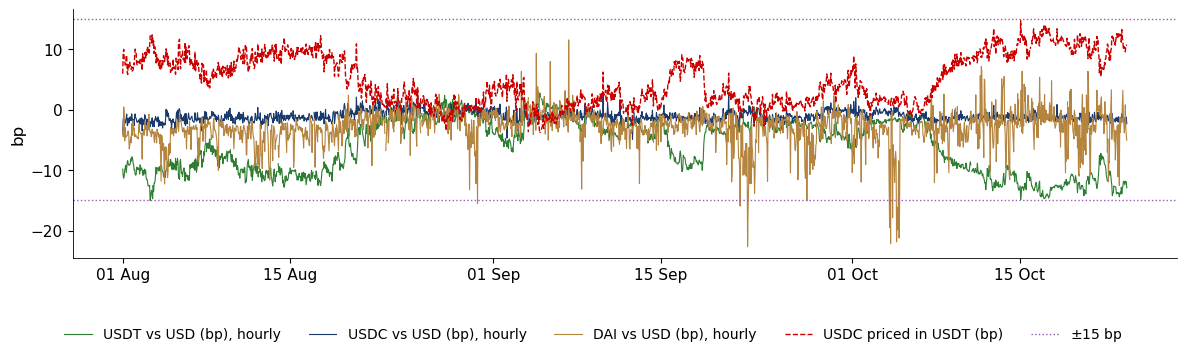

USDT vs USD, mean hourly deviation in August 2026: -6.6 bp
USDT vs USD, mean hourly deviation in September 2026: -3.2 bp
USDT vs USD, mean hourly deviation in October (to 23 Oct) 2026: -8.7 bp
USDC priced in USDT, October 2026: mean 7.5 bp, maximum 14.7 bp at 2026-10-15 02:00:00 UTC
hours above 10 bp: 206 of 552; hours above 15 bp: 0


In [21]:
rec = H.loc['2026-08-01':]
fig, ax = plt.subplots(figsize=(12, 3.6))
for s in ['USDT', 'USDC', 'DAI']:
    ax.plot(rec.index, 1e4 * (rec[s] - 1), color=COL[s], lw=0.8, label=f'{s} vs USD (bp), hourly')
ax.plot(rec.index, dh.loc['2026-08-01':], color=RED, lw=1, ls='--', label='USDC priced in USDT (bp)')
ax.axhline(15, color=ETH, ls=':', lw=1, label='$\\pm$15 bp')
ax.axhline(-15, color=ETH, ls=':', lw=1)
ax.set_ylabel('bp'); ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
finish_fig(fig, 'ba_l4_recent', ncol=5, bottom=0.15)

tt = 1e4 * (H['USDT'] - 1)
for m, a, b in [('August', '2026-08-01', '2026-08-31'), ('September', '2026-09-01', '2026-09-30'), ('October (to 23 Oct)', '2026-10-01', END)]:
    print(f'USDT vs USD, mean hourly deviation in {m} 2026: {tt.loc[a:b].mean():.1f} bp')
lastm = dh.loc['2026-10-01':]
print(f'USDC priced in USDT, October 2026: mean {lastm.mean():.1f} bp, maximum {lastm.max():.1f} bp at {lastm.idxmax()} UTC')
print(f'hours above 10 bp: {int((lastm >= 10).sum())} of {len(lastm)}; hours above 15 bp: {int((lastm >= 15).sum())}')

USDT traded a few basis points below the dollar for three months, so USDC priced in USDT sat near 10 bp for hundreds of hours without crossing 15 bp.
A rule at 10 bp would have fired repeatedly. The paper's alarm would look at the pool composition and the liquidity curve before calling it stress.

## Further material

### A threshold autoregression

If arbitrage costs $c$, small deviations are not worth trading and large ones are. A threshold autoregressive (TAR) model captures this:

$$ \Delta d_t = \mu + \rho_{in}\, d_{t-1}\,\mathbb 1\{|d_{t-1}| \leq \gamma\} + \rho_{out}\, d_{t-1}\,\mathbb 1\{|d_{t-1}| > \gamma\} + \varepsilon_t . $$

The band hypothesis is $\rho_{in} \approx 0$ and $\rho_{out} < 0$; the half-life of a deviation is $h = \ln 0.5 / \ln(1 + \rho)$.

- Estimation: for each $\gamma$ on a grid (the 70% to 99.5% quantiles of $|d_{t-1}|$), ordinary least squares (OLS); $\hat\gamma$ minimises the sum of squared residuals (SSR).
- Test of a threshold effect, $H_0: \rho_{in} = \rho_{out}$. Under $H_0$ the threshold $\gamma$ is not identified, so the usual $\chi^2$ distribution does not apply. With a heteroskedasticity-consistent (HC) variance,

$$ \sup W = \sup_{\gamma \in \Gamma} W(\gamma), \qquad W(\gamma) = \frac{(\hat\rho_{in} - \hat\rho_{out})^2}{\widehat{\mathrm{Var}}_{\mathrm{HC}}(\hat\rho_{in} - \hat\rho_{out})} . $$

- p-value by the fixed-regressor bootstrap of [Hansen (1996)](https://doi.org/10.2307/2171789): $y_t^\ast = \hat e_t z_t$ with $z_t \sim N(0,1)$ and $\hat e_t$ the residuals of the linear AR(1), recompute $\sup W$, $B = 199$ times.

In [22]:
x0 = dh.shift(1); dy = dh - x0
ok = dy.notna() & x0.notna()
y_, x_ = dy[ok].values, x0[ok].values
n = len(y_)
rvec = np.array([0, 1, -1.0])


def tar_fit(X, y):
    """OLS with HC0 variance; Wald statistic for rho_in = rho_out."""
    iX = np.linalg.inv(X.T @ X)
    b = iX @ (X.T @ y)
    e = y - X @ b
    V = iX @ (X.T * e ** 2) @ X @ iX
    return (rvec @ b) ** 2 / (rvec @ V @ rvec), b, e, V


grid = np.unique(np.quantile(np.abs(x_), np.linspace(0.70, 0.995, 60)))
Xs = [np.column_stack([np.ones(n), x_ * (np.abs(x_) <= g), x_ * (np.abs(x_) > g)]) for g in grid]
fits = [tar_fit(X, y_) for X in Xs]
W = np.array([f[0] for f in fits]); SSR = np.array([(f[2] ** 2).sum() for f in fits])
k_hat = int(np.argmin(SSR)); gh = grid[k_hat]
wh, bh, eh, Vh = fits[k_hat]
se = np.sqrt(np.diag(Vh))
supW = W.max()
X0 = np.column_stack([np.ones(n), x_])
b0 = np.linalg.solve(X0.T @ X0, X0.T @ y_); e0 = y_ - X0 @ b0

rng = np.random.default_rng(11)
B = 199
iXs = [np.linalg.inv(X.T @ X) for X in Xs]
supb = []
for _ in range(B):
    ys = e0 * rng.standard_normal(n)
    best = 0
    for X, iX in zip(Xs, iXs):
        b = iX @ (X.T @ ys); e = ys - X @ b
        V = iX @ (X.T * e ** 2) @ X @ iX
        best = max(best, (rvec @ b) ** 2 / (rvec @ V @ rvec))
    supb.append(best)
pboot = (np.array(supb) >= supW).mean()
hl = lambda rho: np.log(0.5) / np.log(1 + rho) if -1 < rho < 0 else np.inf
inn = np.abs(x_) <= gh
print(f'hourly USDC/USDT, n = {n} consecutive pairs; estimated threshold gamma = {gh:.1f} bp; share of hours inside the band = {100 * inn.mean():.1f}%')
pd.DataFrame({'coefficient': [bh[1], bh[2], b0[1]], 'SE (HC)': [se[1], se[2], np.nan],
              'half-life (hours)': [hl(bh[1]), hl(bh[2]), hl(b0[1])]},
             index=['rho_in (inside the band)', 'rho_out (outside the band)', 'rho, linear AR(1)']).round(4)

hourly USDC/USDT, n = 40545 consecutive pairs; estimated threshold gamma = 22.5 bp; share of hours inside the band = 99.0%


,coefficient,SE (HC),half-life (hours)
rho_in (inside the band),-0.0396,0.0020,17.1663
rho_out (outside the band),-0.0233,0.0297,29.3609
"rho, linear AR(1)",-0.0245,NaN,27.9612


sup W = 0.46; bootstrap 95% critical value = 4.65; bootstrap p-value = 0.653 (B = 199)


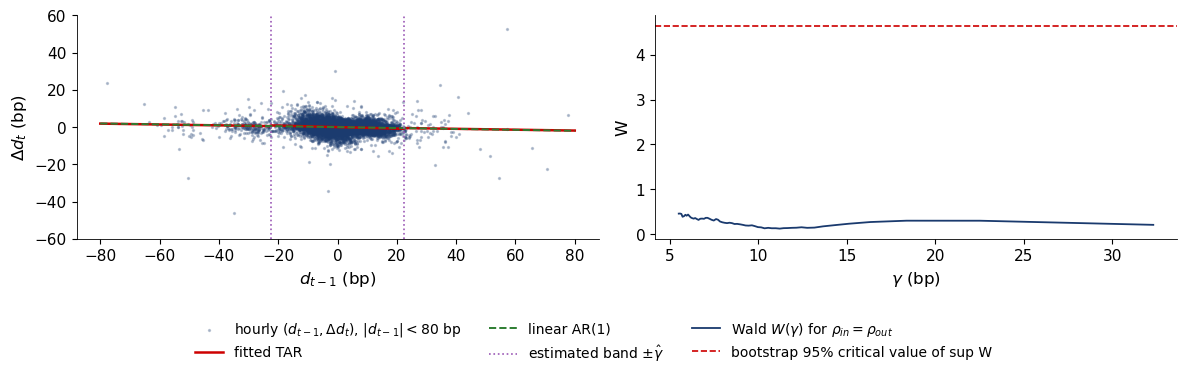

In [23]:
print(f'sup W = {supW:.2f}; bootstrap 95% critical value = {np.quantile(supb, 0.95):.2f}; bootstrap p-value = {pboot:.3f} (B = {B})')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
m = np.abs(x_) < 80
ax[0].scatter(x_[m], y_[m], s=2, color=BLUE, alpha=0.25, label=r'hourly $(d_{t-1}, \Delta d_t)$, $|d_{t-1}| < 80$ bp')
xx = np.linspace(-80, 80, 400)
ax[0].plot(xx, bh[0] + np.where(np.abs(xx) <= gh, bh[1], bh[2]) * xx, color=RED, lw=1.8, label='fitted TAR')
ax[0].plot(xx, b0[0] + b0[1] * xx, color=GREEN, ls='--', lw=1.4, label='linear AR(1)')
for g in (gh, -gh):
    ax[0].axvline(g, color=ETH, ls=':', lw=1.2, label=(r'estimated band $\pm\hat\gamma$' if g > 0 else None))
ax[0].set_xlabel(r'$d_{t-1}$ (bp)'); ax[0].set_ylabel(r'$\Delta d_t$ (bp)'); ax[0].set_ylim(-60, 60)
ax[1].plot(grid, W, color=BLUE, label=r'Wald $W(\gamma)$ for $\rho_{in} = \rho_{out}$')
ax[1].axhline(np.quantile(supb, 0.95), color=RED, ls='--', lw=1.2, label='bootstrap 95% critical value of sup W')
ax[1].set_xlabel(r'$\gamma$ (bp)'); ax[1].set_ylabel('W')
finish_fig(fig, 'ba_l4_tar', ncol=3, bottom=0.18)

There is no threshold effect: we cannot reject $\rho_{in} = \rho_{out}$, and deviations decay in about a day either way.
The slopes are small (about $-0.04$), so at the hourly scale reversion is slow.
The band story fails in this sample because the large deviations are the SVB and Terra hours, when redemption was closed or trust was gone: arbitrage was not available, so reversion was *not* faster.
A band model describes normal times; stress is a change of regime, not a larger deviation of the same process.

### Worked example: how fast does a deviation close?

Inside the band, the expected deviation after $h$ hours is $E[d_{t+h} \mid d_t] \approx (1 + \hat\rho_{in})^h\, d_t$ (with $\hat\mu \approx 0$). Start from $d_t = -12$ bp:

In [24]:
d0 = -12
print(f'factor after 24 hours (1 + rho_in)^24 = {(1 + bh[1]) ** 24:.3f}; expected deviation after 24 hours = {d0 * (1 + bh[1]) ** 24:.1f} bp')
print(f'half-life = ln 0.5 / ln(1 + rho_in) = {hl(bh[1]):.1f} hours')

factor after 24 hours (1 + rho_in)^24 = 0.379; expected deviation after 24 hours = -4.6 bp
half-life = ln 0.5 / ln(1 + rho_in) = 17.2 hours


A deviation of this size is expected to shrink by about 60% in a day. If it does not, the process is not "inside the band", and that persistence is itself a warning signal.

### Curve 3pool: entropy as an imbalance index

The Curve 3pool holds DAI, USDC and USDT. With normalised balances $w_{\mathrm{DAI}} + w_{\mathrm{USDC}} + w_{\mathrm{USDT}} = 1$, the paper uses the entropy

$$ S_{3pool} = -\sum_i w_i \ln w_i, \qquad 0 \leq S \leq \ln 3 = 1.0986 . $$

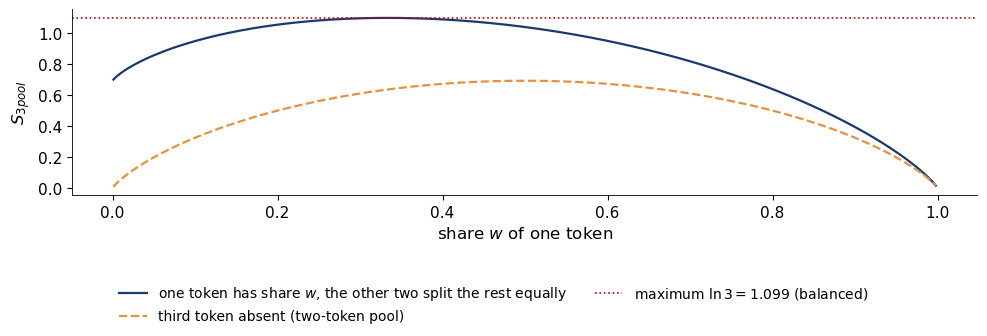

entropy, balanced (1/3, 1/3, 1/3): 1.0986
entropy, mild (0.20, 0.40, 0.40): 1.0549
entropy, stress (0.05, 0.10, 0.85): 0.5182


In [25]:
S = lambda ws: -sum(u * np.log(u) for u in ws if u > 0)
w = np.linspace(0.001, 0.998, 400)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(w, [S([u, (1 - u) / 2, (1 - u) / 2]) for u in w], color=BLUE, lw=1.6, label='one token has share $w$, the other two split the rest equally')
ax.plot(w, [S([u, 1 - u - 1e-12, 1e-12]) for u in w], color=BTC, lw=1.6, ls='--', label='third token absent (two-token pool)')
ax.axhline(np.log(3), color=RED, ls=':', lw=1.2, label=r'maximum $\ln 3 = 1.099$ (balanced)')
ax.set_xlabel('share $w$ of one token'); ax.set_ylabel(r'$S_{3pool}$')
finish_fig(fig, 'ba_l4_entropy', ncol=2, bottom=0.22)
for name, ws in {'balanced (1/3, 1/3, 1/3)': [1 / 3] * 3, 'mild (0.20, 0.40, 0.40)': [0.20, 0.40, 0.40], 'stress (0.05, 0.10, 0.85)': [0.05, 0.10, 0.85]}.items():
    print(f'entropy, {name}: {S(ws):.4f}')

The entropy is flat near balance and steep near a corner: small changes at high levels are noise, while a fall below about 1 signals stress.

### A fixed basis for a moving liquidity curve

On Uniswap V3, liquidity providers choose a price range; prices live on ticks $p_k = 1.0001^k$ (one tick is 1 bp), and the active liquidity at each tick forms a curve that changes every hour.
The paper maps the ticks around the peg to $x \in [-1, 1]$ (peg at $x = 0$), takes the log-liquidity $\ell_t(x) = \log\{L_t(x) + 1\}$, and expands it in Gegenbauer polynomials, which are orthonormal under the weight $w_\alpha$:

$$ \ell_t(x) \approx \sum_{k=0}^{K} \beta_{t,k}\, \phi_k^{(\alpha)}(x), \qquad w_\alpha(x) = (1 - x^2)^{\alpha - 1/2}, \qquad \beta_{t,k} = \int_{-1}^{1} \ell_t(x)\,\phi_k^{(\alpha)}(x)\,w_\alpha(x)\,dx . $$

$k = 0$ measures the level of liquidity, $k = 1$ the left-right asymmetry, $k = 2$ the concentration at the peg; odd $k$ are asymmetric and even $k$ symmetric.
The energies are $E_t^{odd} = \sum_{k \text{ odd}} \beta_{t,k}^2$ and $E_t^{even} = \sum_{k \geq 2 \text{ even}} \beta_{t,k}^2$.

Worked example: a stylised curve with a deep band at the peg, extra depth below parity and a cliff above $x = 0.5$, with $\alpha = 0.3$ and $K = 7$, fitted by weighted least squares on 101 ticks; then its mirror image.

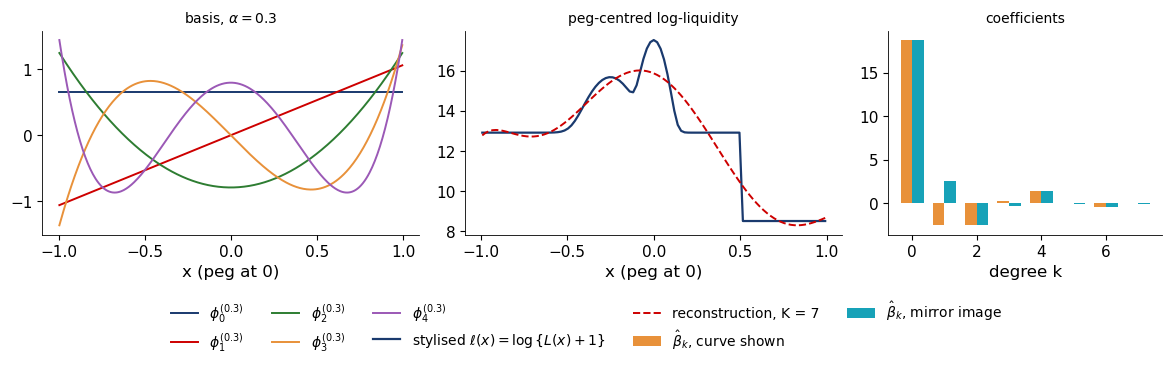

odd energy E_odd = 6.48; even energy E_even = 8.55


,"beta_k, curve","beta_k, mirror image"
degree k,,
0,18.783,18.783
1,-2.525,2.525
2,-2.504,-2.504
3,0.316,-0.316
4,1.448,1.448
5,0.076,-0.076
6,-0.428,-0.428
7,0.071,-0.071


In [26]:
from scipy import special

alpha = 0.3


def phi(k, x, a=alpha):
    """Orthonormal Gegenbauer polynomial of degree k."""
    h = np.pi * 2 ** (1 - 2 * a) * special.gamma(k + 2 * a) / (special.factorial(k) * (k + a) * special.gamma(a) ** 2)
    return special.eval_gegenbauer(k, a, x) / np.sqrt(h)


xg = -1 + (2 * np.arange(101) + 1) / 101
wg = (1 - xg ** 2) ** (alpha - 0.5)
L = 4e7 * np.exp(-(xg / 0.06) ** 2) + 6e6 * np.exp(-((xg + 0.25) / 0.12) ** 2) + 4e5 * (xg < 0.5) + 5e3
Ls = 4e7 * np.exp(-(xg / 0.06) ** 2) + 6e6 * np.exp(-((xg - 0.25) / 0.12) ** 2) + 4e5 * (xg > -0.5) + 5e3     # mirror image
ell = np.log(L + 1)
K = 7
Phi = np.column_stack([phi(k, xg) for k in range(K + 1)])
Wm = np.diag(wg)
beta = np.linalg.solve(Phi.T @ Wm @ Phi, Phi.T @ Wm @ ell)
beta_m = np.linalg.solve(Phi.T @ Wm @ Phi, Phi.T @ Wm @ np.log(Ls + 1))
fit = Phi @ beta

fig, ax = plt.subplots(1, 3, figsize=(12, 3.7), gridspec_kw={'width_ratios': [1.1, 1.1, 0.8]})
xx = np.linspace(-0.995, 0.995, 400)
for k, col in zip(range(5), [BLUE, RED, GREEN, BTC, ETH]):
    ax[0].plot(xx, phi(k, xx), color=col, lw=1.4, label=f'$\\phi_{k}^{{(0.3)}}$')
ax[0].set_xlabel('x (peg at 0)'); ax[0].set_title(r'basis, $\alpha = 0.3$', fontsize=10)
ax[1].plot(xg, ell, color=BLUE, lw=1.6, label=r'stylised $\ell(x) = \log\{L(x)+1\}$')
ax[1].plot(xg, fit, color=RED, ls='--', lw=1.4, label='reconstruction, K = 7')
ax[1].set_xlabel('x (peg at 0)'); ax[1].set_title('peg-centred log-liquidity', fontsize=10)
ax[2].bar(np.arange(K + 1) - 0.18, beta, width=0.36, color=BTC, label=r'$\hat\beta_k$, curve shown')
ax[2].bar(np.arange(K + 1) + 0.18, beta_m, width=0.36, color=TEAL, label=r'$\hat\beta_k$, mirror image')
ax[2].set_xlabel('degree k'); ax[2].set_title('coefficients', fontsize=10)
finish_fig(fig, 'ba_l4_gegenbauer', ncol=5, bottom=0.18)
print(f'odd energy E_odd = {(beta[1::2] ** 2).sum():.2f}; even energy E_even = {(beta[2::2] ** 2).sum():.2f}')
pd.DataFrame({'beta_k, curve': beta, 'beta_k, mirror image': beta_m}, index=pd.Index(range(K + 1), name='degree k')).round(3)

The mirror image has the *same* even coefficients and odd coefficients with the opposite sign: the odd scores carry the direction of fragility.
A fixed basis keeps the scores comparable over time, unlike a rolling functional principal component analysis (FPCA).

### What drives the warnings? SHAP attribution in the paper

SHapley Additive exPlanations (SHAP; [Lundberg & Lee, 2017](https://arxiv.org/abs/1705.07874)) split each prediction into additive contributions, $f(\mathbf x) = \phi_0 + \sum_j \phi_j(\mathbf x)$.
The paper groups the mean absolute contributions $|\phi_j|$ of the CatBoost model by economic block:

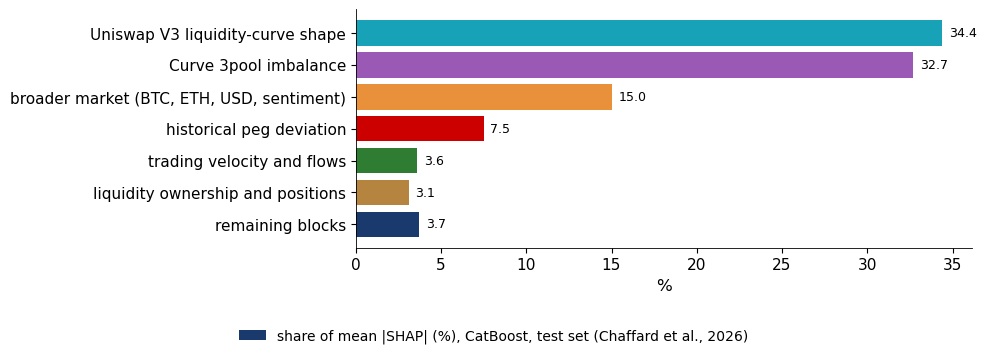

In [27]:
groups = {'Uniswap V3 liquidity-curve shape': 34.4, 'Curve 3pool imbalance': 32.7, 'broader market (BTC, ETH, USD, sentiment)': 15.0,
          'historical peg deviation': 7.5, 'trading velocity and flows': 3.6, 'liquidity ownership and positions': 3.1}
groups['remaining blocks'] = round(100 - sum(groups.values()), 1)
names = list(groups)[::-1]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.barh(names, [groups[k] for k in names], color=[TEAL, ETH, BTC, RED, GREEN, GOLD, BLUE][::-1],
        label='share of mean |SHAP| (%), CatBoost, test set (Chaffard et al., 2026)')
for i, k in enumerate(names):
    ax.text(groups[k] + 0.4, i, f'{groups[k]:.1f}', va='center', fontsize=9)
ax.set_xlabel('%')
finish_fig(fig, 'ba_l4_paper_shap', ncol=1, bottom=0.12)

Past peg deviations explain only 7.5% of the attribution: the model warns from the liquidity shape and the 3pool imbalance, not from the price itself.
This is attribution, not causality: correlated on-chain features share the credit.

### From an alarm to a distribution: a quantile function with Pareto tails

An alarm says *whether*; a risk manager also needs *how far*. The paper forecasts the full conditional distribution of $d_{t+h}$ through its quantile function: a monotone spline body $Q_t^B(u)$ between the levels $\tau_L$ and $\tau_U$, and generalised Pareto distribution (GPD) tails joined smoothly at those levels:

$$ Q_t(u) = \begin{cases} z_L - \dfrac{\beta_L}{\xi_L}\Big[\big(\tfrac{u}{\tau_L}\big)^{-\xi_L} - 1\Big], & u < \tau_L \\[2mm] Q_t^B(u), & \tau_L \leq u \leq \tau_U \\[1mm] z_U + \dfrac{\beta_U}{\xi_U}\Big[\big(\tfrac{1-u}{1-\tau_U}\big)^{-\xi_U} - 1\Big], & u > \tau_U \end{cases} $$

with $z_L = Q^B_t(\tau_L)$, $\beta_L = \tau_L\,Q_t^{B\prime}(\tau_L)$, and symmetrically for the upper tail. For $\xi \geq 1/2$ the tail has infinite variance.

Illustration: a Gaussian body with sd 3 bp, splice points at 5% and 95%, and three choices of the tail parameters. The horizontal axis is on the normal-quantile scale, on which the Gaussian is a straight line.

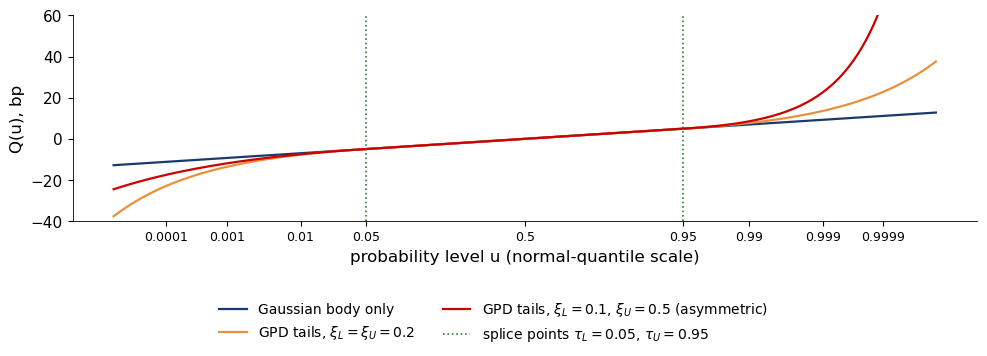

99.9% quantile, Gaussian body only: 9.3 bp
xi_L = 0.2, xi_U = 0.2: 0.1% quantile -13.6 bp, 99.9% quantile 13.6 bp
xi_L = 0.1, xi_U = 0.5: 0.1% quantile -11.9 bp, 99.9% quantile 22.6 bp


In [28]:
tl, tu, s_b = 0.05, 0.95, 3.0
QB = lambda uu: s_b * stats.norm.ppf(uu)
dQ = lambda uu: s_b / stats.norm.pdf(stats.norm.ppf(uu))


def Qspl(uu, xl, xu):
    """Gaussian body with GPD tails below tau_L and above tau_U."""
    uu = np.asarray(uu, dtype=float)
    zl, zu = QB(tl), QB(tu); bl, bu = tl * dQ(tl), (1 - tu) * dQ(tu)
    out = QB(np.clip(uu, tl, tu))
    m1, m2 = uu < tl, uu > tu
    out[m1] = zl - bl / xl * ((uu[m1] / tl) ** (-xl) - 1)
    out[m2] = zu + bu / xu * (((1 - uu[m2]) / (1 - tu)) ** (-xu) - 1)
    return out


uu = np.concatenate([np.logspace(-5, np.log10(0.5), 1000), 1 - np.logspace(np.log10(0.5), -5, 1000)[1:]])
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(stats.norm.ppf(uu), QB(uu), color=BLUE, lw=1.6, label='Gaussian body only')
ax.plot(stats.norm.ppf(uu), Qspl(uu, 0.2, 0.2), color=BTC, lw=1.6, label=r'GPD tails, $\xi_L = \xi_U = 0.2$')
ax.plot(stats.norm.ppf(uu), Qspl(uu, 0.1, 0.5), color=RED, lw=1.6, label=r'GPD tails, $\xi_L = 0.1$, $\xi_U = 0.5$ (asymmetric)')
for t_ in (tl, tu):
    ax.axvline(stats.norm.ppf(t_), color=GREEN, ls=':', lw=1.2, label=(r'splice points $\tau_L = 0.05$, $\tau_U = 0.95$' if t_ == tl else None))
ax.set_xticks(stats.norm.ppf([1e-4, 1e-3, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999, 0.9999]))
ax.set_xticklabels(['0.0001', '0.001', '0.01', '0.05', '0.5', '0.95', '0.99', '0.999', '0.9999'], fontsize=9)
ax.set_xlabel('probability level u (normal-quantile scale)'); ax.set_ylabel('Q(u), bp'); ax.set_ylim(-40, 60)
finish_fig(fig, 'ba_l4_gpd', ncol=2, bottom=0.2)
print(f'99.9% quantile, Gaussian body only: {QB(0.999):.1f} bp')
for xl, xu in [(0.2, 0.2), (0.1, 0.5)]:
    print(f'xi_L = {xl}, xi_U = {xu}: 0.1% quantile {Qspl([0.001], xl, xu)[0]:.1f} bp, 99.9% quantile {Qspl([0.999], xl, xu)[0]:.1f} bp')

A heavier upper tail ($\xi_U = 0.5$) more than doubles the 99.9% quantile of the Gaussian, while the lower tail with $\xi_L = 0.1$ stays close to it: separate tail parameters let USDC and USDT depegs differ.

### Scoring a distribution: CRPS and twCRPS

The continuous ranked probability score ([Gneiting & Raftery, 2007](https://doi.org/10.1198/016214506000001437)) is a proper scoring rule for a forecast given by its cumulative distribution function (CDF) $F$, or its quantile function $Q = F^{-1}$, and an outcome $y$:

$$ \mathrm{CRPS}(F, y) = \int_{-\infty}^{\infty} \big(F(x) - \mathbb 1\{y \leq x\}\big)^2 dx = 2\int_0^1 \rho_u\big(y - Q(u)\big)\,du, $$

where $\rho_u(e) = e\,(u - \mathbb 1\{e < 0\})$ is the pinball loss. For a Normal forecast, $\mathrm{CRPS}(N(\mu, \sigma^2), y) = \sigma\big[z(2\Phi(z) - 1) + 2\varphi(z) - 1/\sqrt\pi\big]$ with $z = (y - \mu)/\sigma$.
The threshold-weighted CRPS ([Gneiting & Ranjan, 2011](https://doi.org/10.1198/jbes.2010.08110)) puts the weight where depegs are:

$$ \mathrm{twCRPS} = 2\int_0^1 \rho_u\big(v(y) - v(Q(u))\big)\,du, \quad v(r) = \int_0^r w(s)\,ds, \quad w(r) = \sigma\Big(\frac{r - \delta}{h}\Big) + \sigma\Big(\frac{-r - \delta}{h}\Big), $$

with $\sigma(\cdot)$ the logistic function. Worked example: three forecasts, three outcomes ($\delta = 15$, $h = 2$, illustrative). The integrals over $u$ are approximated on 999 equally spaced levels.

In [29]:
def crps_norm(mu, s, y):
    z = (y - mu) / s
    return s * (z * (2 * stats.norm.cdf(z) - 1) + 2 * stats.norm.pdf(z) - 1 / np.sqrt(np.pi))


u = (np.arange(1, 1000) - 0.5) / 999
pin = lambda uu, e: e * (uu - (e < 0))
sig = lambda r: 1 / (1 + np.exp(-r))
delta, hh = 15.0, 2.0
rr = np.linspace(-60, 60, 24001)
wfun = sig((rr - delta) / hh) + sig((-rr - delta) / hh)
Vc = np.concatenate([[0], np.cumsum((wfun[1:] + wfun[:-1]) / 2 * np.diff(rr))])
Vc -= np.interp(0, rr, Vc)
vt = lambda r: np.interp(r, rr, Vc)
crps_q = lambda q, y: 2 * (pin(u, y - q)).mean()
tw_q = lambda q, y: 2 * (pin(u, vt(y) - vt(q))).mean()
rows = {}
for name, q in [('N(0, 5^2)', stats.norm.ppf(u, 0, 5)), ('N(0, 10^2)', stats.norm.ppf(u, 0, 10)), ('t3, scale 3', stats.t.ppf(u, 3) * 3)]:
    rows[name] = {**{f'CRPS, y = {y:g}': crps_q(q, y) for y in [1, 12, 25]}, **{f'twCRPS, y = {y:g}': tw_q(q, y) for y in [1, 12, 25]}}
print(f'check: closed-form CRPS of N(0, 5^2) at y = 12 is {crps_norm(0, 5, 12):.3f}')
pd.DataFrame(rows).T.round(3)

check: closed-form CRPS of N(0, 5^2) at y = 12 is 9.206


,"CRPS, y = 1","CRPS, y = 12","CRPS, y = 25","twCRPS, y = 1","twCRPS, y = 12","twCRPS, y = 25"
"N(0, 5^2)",1.248,9.206,22.180,0.003,0.378,9.980
"N(0, 10^2)",2.377,7.480,19.398,0.054,0.324,9.343
"t3, scale 3",0.948,9.705,22.566,0.003,0.381,9.910


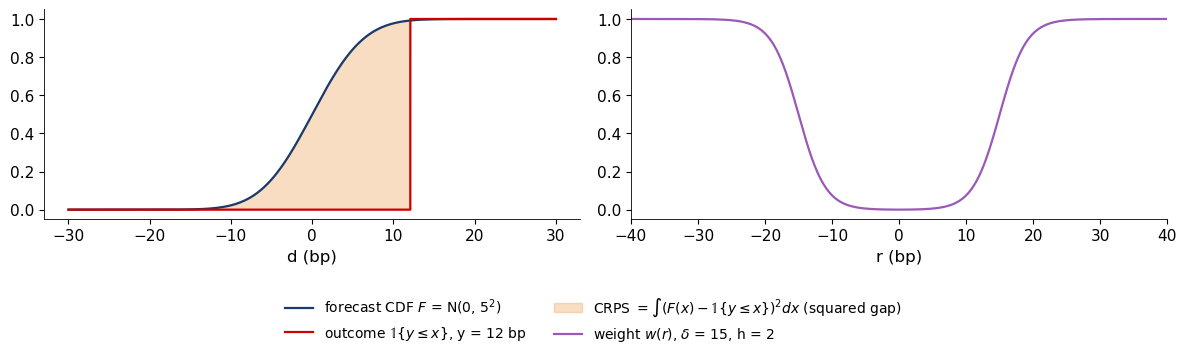

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
xs = np.linspace(-30, 30, 600)
ax[0].plot(xs, stats.norm.cdf(xs, 0, 5), color=BLUE, lw=1.6, label=r'forecast CDF $F$ = N(0, 5$^2$)')
ax[0].step(xs, (xs >= 12).astype(float), color=RED, lw=1.6, where='post', label=r'outcome $\mathbb{1}\{y \leq x\}$, y = 12 bp')
ax[0].fill_between(xs, stats.norm.cdf(xs, 0, 5), (xs >= 12).astype(float), color=BTC, alpha=0.3,
                   label=r'CRPS $= \int (F(x) - \mathbb{1}\{y \leq x\})^2 dx$ (squared gap)')
ax[0].set_xlabel('d (bp)')
ax[1].plot(rr, wfun, color=ETH, lw=1.6, label=r'weight $w(r)$, $\delta$ = 15, h = 2')
ax[1].set_xlabel('r (bp)'); ax[1].set_xlim(-40, 40)
finish_fig(fig, 'ba_l4_crps', ncol=2, bottom=0.2)

In a calm hour ($y = 1$) the sharp forecasts win; in a depeg hour ($y = 25$) the wide one wins. The twCRPS almost ignores calm hours and scores only the depeg region.

### Results in the paper: distributional accuracy

The paper compares its model (spline body, GPD tails, twCRPS training loss) with a naive forecast, an autoregressive integrated moving average (ARIMA) model, GARCH with Student-t errors (GARCH-t), and two neural benchmarks, the Time-series Dense Encoder (TiDE) and TimeXer, on the test period January 2025 – May 2026 (Table 2 of the paper).

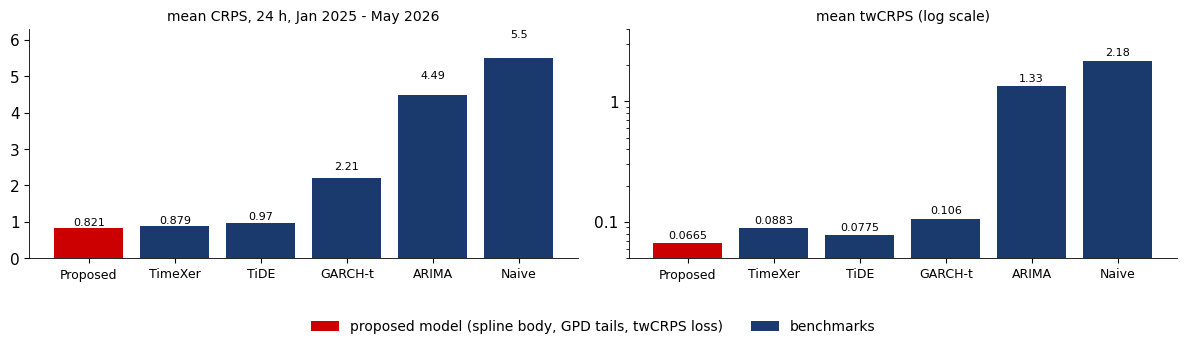

reduction of the proposed model against each benchmark:


,CRPS reduction (%),twCRPS reduction (%)
TimeXer,6.6,24.7
TiDE,15.4,14.2
GARCH-t,62.9,37.3
ARIMA,81.7,95.0
Naive,85.1,96.9


In [31]:
T2 = {'Proposed': (0.8205, 0.0665), 'TimeXer': (0.8787, 0.0883), 'TiDE': (0.9702, 0.0775), 'GARCH-t': (2.2140, 0.1060),
      'ARIMA': (4.4917, 1.3344), 'Naive': (5.4997, 2.1775)}            # (mean CRPS, mean twCRPS), 24-hour horizon
nm = list(T2)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(nm[:1], [T2[nm[0]][0]], color=RED, label='proposed model (spline body, GPD tails, twCRPS loss)')
ax[0].bar(nm[1:], [T2[k][0] for k in nm[1:]], color=BLUE, label='benchmarks')
ax[1].bar(nm, [T2[k][1] for k in nm], color=[RED] + [BLUE] * 5)
ax[0].set_title('mean CRPS, 24 h, Jan 2025 - May 2026', fontsize=10); ax[1].set_title('mean twCRPS (log scale)', fontsize=10)
ax[1].set_yscale('log'); ax[1].yaxis.set_major_formatter(plt.matplotlib.ticker.FormatStrFormatter('%g'))
for a_, j in zip(ax, [0, 1]):
    a_.tick_params(axis='x', labelsize=9)
    for i, k in enumerate(nm):
        a_.text(i, T2[k][j] * 1.1, f'{T2[k][j]:.3g}', ha='center', fontsize=8)
ax[0].set_ylim(0, 6.3); ax[1].set_ylim(0.05, 4)
finish_fig(fig, 'ba_l4_paper_t2', ncol=2, bottom=0.13)
red = pd.DataFrame({k: {'CRPS reduction (%)': 100 * (1 - T2['Proposed'][0] / T2[k][0]),
                        'twCRPS reduction (%)': 100 * (1 - T2['Proposed'][1] / T2[k][1])} for k in nm[1:]}).T
print('reduction of the proposed model against each benchmark:')
red.round(1)

Against GARCH-t the proposed model cuts the CRPS from 2.21 to 0.82 (63%) and the twCRPS from 0.106 to 0.067 (37%).

### Calibration and ablation in the paper

The ablation removes one component at a time and reports how much worse the quantile (pinball) loss (QL) becomes at the 1% and 99% levels (Table 4 of the paper).

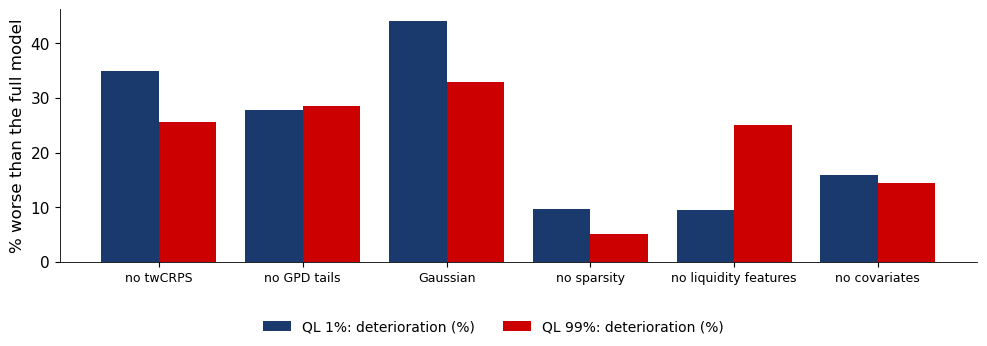

In [32]:
T4 = {'no twCRPS': (-35.0, -25.6), 'no GPD tails': (-27.8, -28.5), 'Gaussian': (-44.0, -33.0), 'no sparsity': (-9.6, -5.1),
      'no liquidity features': (-9.5, -25.0), 'no covariates': (-15.8, -14.4)}
nm = list(T4); a = np.arange(len(nm))
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(a - 0.2, [-T4[k][0] for k in nm], width=0.4, color=BLUE, label='QL 1%: deterioration (%)')
ax.bar(a + 0.2, [-T4[k][1] for k in nm], width=0.4, color=RED, label='QL 99%: deterioration (%)')
ax.set_xticks(a); ax.set_xticklabels(nm, fontsize=9); ax.set_ylabel('% worse than the full model')
finish_fig(fig, 'ba_l4_paper_ablation', ncol=2, bottom=0.12)

A Gaussian output head loses 44% at the 1% quantile; dropping the liquidity features costs 25% at the 99% quantile, more than dropping all covariates.